# Generate a new latent point and a new mask image

This example samples a point that is absent from the observed
320-dimensional embeddings, synthesizes its spatial features, and
decodes a **new crack/busbar/dark mask image**. It displays the sampled
point in the latent space and checks that the binary image is different
from every example input.

The bundled model is a deterministic skip-connected autoencoder.
Its decoder uses spatial bottleneck and encoder skip maps, so synthesis
must supply those maps along with the pooled latent point. We draw
random convex weights over several observed examples and apply those
weights consistently at all feature levels. This is empirical feature
interpolation with the trained decoder, rather than a learned VAE prior.
It generates segmented mask images, not raw EL photographs.

Install the runtime with `python -m pip install -e .` from this checkout.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

from pvcracks.vae import load_unet_ae_crack_plus
from pvcracks.vae.features import CHANNELS, extract_features, prepare_masks
from pvcracks.vae.inference import reconstruct_masks, reconstruction_scores

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "docs/data/autoencoder_3ch_module_209.npz").is_file())
DATA = ROOT / "docs/data"
DEVICE = "cpu"  # Set to "cuda" for a compatible GPU.
BATCH_SIZE = 4
SEED = 30
masks = np.load(DATA / "autoencoder_3ch_module_209.npz")["masks"]
metadata = pd.read_csv(DATA / "autoencoder_3ch_module_209.csv")
model, checkpoint = load_unet_ae_crack_plus(device=DEVICE)
print(f"{len(masks)} inputs; {model.latent_dim} embedding coordinates; device={DEVICE}")

26 inputs; 320 embedding coordinates; device=cpu


## Encode the observed mask images

PCA below is a view of the learned space. The synthesis itself operates
on the original feature maps; it does not decode a 2D PCA coordinate.

In [2]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from pvcracks.vae.synthesis import synthesize_masks

features = extract_features(model, masks, batch_size=BATCH_SIZE)
embeddings = features[[f"latent_{i}" for i in range(model.latent_dim)]].to_numpy()
scaler = StandardScaler().fit(embeddings)
pca = PCA(n_components=3, random_state=SEED).fit(scaler.transform(embeddings))
observed_coordinates = pca.transform(scaler.transform(embeddings))

## Sample and decode a new point

Change `SAMPLE_SEED` for another image. Four distinct donors receive
positive Dirichlet weights. The same weights synthesize all skip maps
and the spatial bottleneck. Global average pooling of that bottleneck
gives the sampled 320-value code. No single input is reconstructed here.

In [3]:
SAMPLE_SEED = 6
DONOR_COUNT = 4
sample = synthesize_masks(model, masks, seed=SAMPLE_SEED, donor_count=DONOR_COUNT)
donor_indices = sample["donor_indices"].numpy()
weights = sample["weights"].numpy()
sampled_latent = sample["embedding"].numpy()
generated_probabilities = sample["probabilities"][0].numpy()
generated_mask = sample["masks"][0].numpy()

# Check the sampled point, feature consistency, and pixel-level novelty.
expected_latent = np.sum(embeddings[donor_indices] * weights[:, None], axis=0)
np.testing.assert_allclose(sampled_latent[0], expected_latent, atol=2e-5, rtol=2e-5)
latent_distances = np.linalg.norm(embeddings - sampled_latent, axis=1)
assert np.all(latent_distances > 1e-5), "The sampled point matches an input code"
pixel_difference = np.mean(masks != generated_mask, axis=(1, 2, 3))
assert np.all(pixel_difference > 0), "The generated binary image matches an input"
nearest = int(np.argmin(pixel_difference))
donor_table = metadata.iloc[donor_indices][["Cell_ID"]].copy()
donor_table["weight"] = weights
display(donor_table)
print(f"New code shape: {sampled_latent.shape}")
print(f"Closest input: {metadata.iloc[nearest].Cell_ID}; "
      f"different pixels: {100 * pixel_difference[nearest]:.2f}%")

,Cell_ID,weight
10,209_A1_Init,0.059170
24,209_A1_Deg1,0.389877
12,209_B3_Init,0.309917
8,209_C1_Deg2,0.241035


New code shape: (1, 320)
Closest input: 209_A1_Deg1; different pixels: 1.51%


## Locate the new point in the latent space

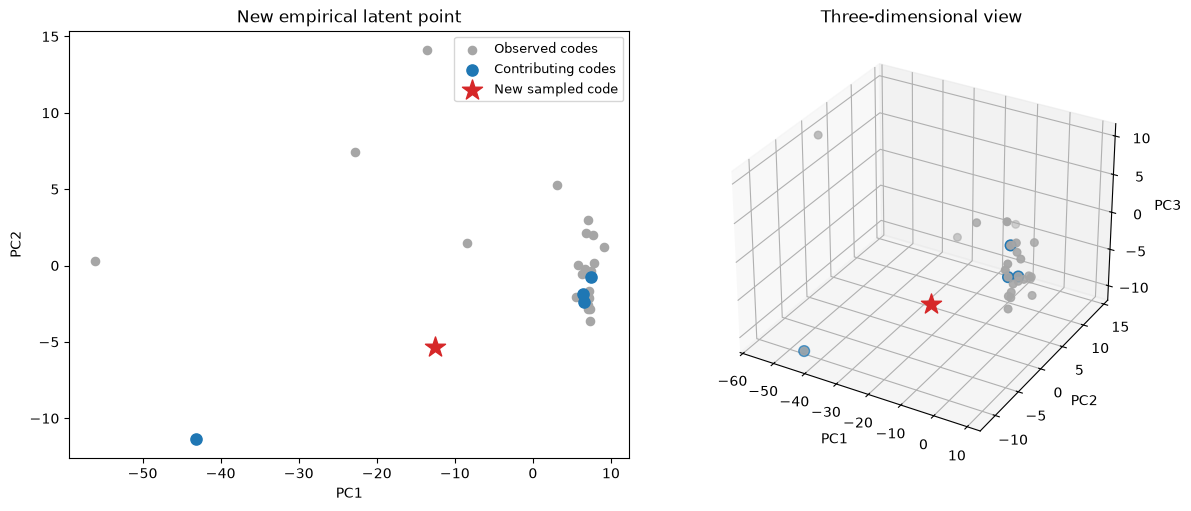

In [4]:
sampled_coordinates = pca.transform(scaler.transform(sampled_latent))
fig = plt.figure(figsize=(12, 5), layout="constrained")
ax2 = fig.add_subplot(121)
ax3 = fig.add_subplot(122, projection="3d")
ax2.scatter(observed_coordinates[:, 0], observed_coordinates[:, 1],
            c="0.65", s=35, label="Observed codes")
ax2.scatter(observed_coordinates[donor_indices, 0], observed_coordinates[donor_indices, 1],
            c="tab:blue", s=65, label="Contributing codes")
ax2.scatter(sampled_coordinates[:, 0], sampled_coordinates[:, 1],
            c="tab:red", marker="*", s=230, label="New sampled code", zorder=5)
ax2.set(xlabel="PC1", ylabel="PC2", title="New empirical latent point")
ax2.legend(fontsize=9)
ax3.scatter(*observed_coordinates.T, c="0.65", s=30)
ax3.scatter(*observed_coordinates[donor_indices].T, c="tab:blue", s=60)
ax3.scatter(*sampled_coordinates.T, c="tab:red", marker="*", s=230)
ax3.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title="Three-dimensional view")
plt.show()

Feature interpolation can smooth thin cracks. The figures show both probabilities and binary masks, and compare the generated crack geometry with its contributing examples.

## Inspect the generated image and the contributing examples

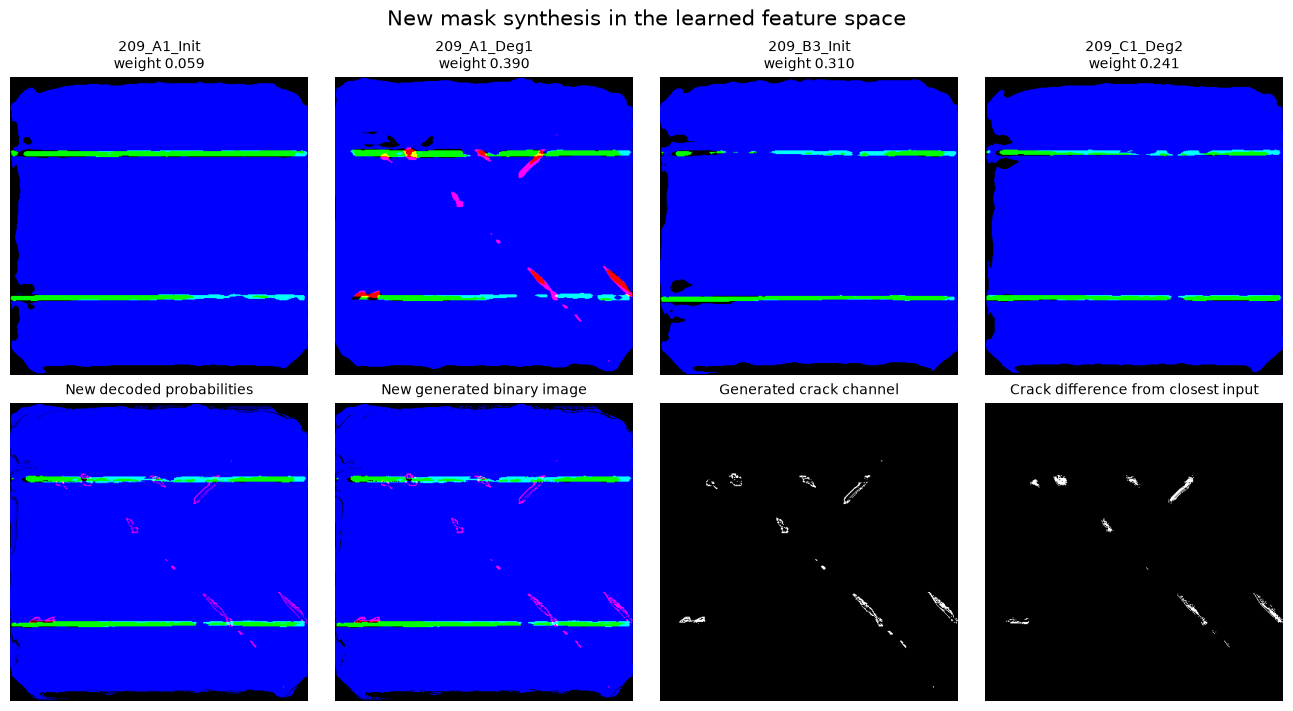

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(13, 7), layout="constrained")
for ax, index, weight in zip(axes[0], donor_indices, weights):
    ax.imshow(masks[index].astype(np.float32).transpose(1, 2, 0))
    ax.set_title(f"{metadata.iloc[index].Cell_ID}\nweight {weight:.3f}", fontsize=10)
    ax.axis("off")
panels = [
    (generated_probabilities.transpose(1, 2, 0), "New decoded probabilities"),
    (generated_mask.transpose(1, 2, 0), "New generated binary image"),
    (generated_mask[0], "Generated crack channel"),
    (masks[nearest, 0] != generated_mask[0], "Crack difference from closest input"),
]
for ax, (image, title) in zip(axes[1], panels):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
fig.suptitle("New mask synthesis in the learned feature space", fontsize=15)
plt.show()

## Save the new image and its latent code

Red, green, and blue represent crack, busbar, and dark masks. The PNG
stores those three binary channels. The probability arrays, latent code,
donor IDs, and seed allow the synthesis to be inspected and reproduced.

In [6]:
OUTPUT = ROOT / "outputs/generated_images"
OUTPUT.mkdir(parents=True, exist_ok=True)
Image.fromarray((generated_mask.transpose(1, 2, 0) * 255).astype(np.uint8)).save(
    OUTPUT / "generated_mask.png")
np.save(OUTPUT / "generated_probabilities.npy", generated_probabilities)
np.save(OUTPUT / "sampled_latent.npy", sampled_latent)
details = {
    "method": "convex synthesis of bottleneck and skip feature maps",
    "seed": SAMPLE_SEED,
    "donors": donor_table.reset_index().to_dict(orient="records"),
    "closest_input": metadata.iloc[nearest].Cell_ID,
    "minimum_pixel_difference_fraction": float(pixel_difference.min()),
}
(OUTPUT / "generation.json").write_text(json.dumps(details, indent=2) + "\n")
print(OUTPUT / "generated_mask.png")

C:\Users\Norman\pvcracks\outputs\generated_images\generated_mask.png
